In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/carrie1/ecommerce-data/data.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score,davies_bouldin_score,calinski_harabasz_score
from sklearn.cluster import KMeans

In [3]:
df = pd.read_csv('/kaggle/input/datasets/carrie1/ecommerce-data/data.csv',encoding='ISO-8859-1')

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


### Inferences:
The dataset consists of 541,909 entries and 8 columns. Here is a brief overview of each column:

**InvoiceNo:** This is an object data type column that contains the invoice number for each transaction. Each invoice number can represent multiple items purchased in a single transaction.

**StockCode:** An object data type column representing the product code for each item.

**Description:** This column, also an object data type, contains descriptions of the products. It has some missing values, with 540,455 non-null entries out of 541,909.

**Quantity:** This is an integer column indicating the quantity of products purchased in each transaction.

**InvoiceDate:** A datetime column that records the date and time of each transaction.

**UnitPrice:** A float column representing the unit price of each product.

**CustomerID:** A float column that contains the customer ID for each transaction. This column has a significant number of missing values, with only 406,829 non-null entries out of 541,909.

**Country:** An object column recording the country where each transaction took place.

From a preliminary overview, it seems that there are missing values in the Description and CustomerID columns which need to be addressed. The InvoiceDate column is already in datetime format, which will facilitate further time series analysis. We also observe that a single customer can have multiple transactions as inferred from the repeated CustomerID in the initial rows.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,1.00,3.00,10.00,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,15287.690570,1713.600303,12346.00,13953.00,15152.00,16791.00,18287.0


In [7]:
df.describe(include='object').T

,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
InvoiceDate,541909,23260,10/31/2011 14:41,1114
Country,541909,38,United Kingdom,495478



### Inferences:
**Quantity:** The average quantity of products in a transaction is approximately 9.55.

The quantity has a wide range, with a minimum value of -80995 and a maximum value of 80995. The negative values indicate returned or cancelled orders, which need to be handled appropriately.

The standard deviation is quite large, indicating a significant spread in the data. The presence of outliers is indicated by a large difference between the maximum and the 75th percentile values.

**UnitPrice:** The average unit price of the products is approximately 4.61.

The unit price also shows a wide range, from -11062.06 to 38970, which suggests the presence of errors or noise in the data, as negative prices don't make sense.

Similar to the Quantity column, the presence of outliers is indicated by a large difference between the maximum and the 75th percentile values.

**CustomerID:** There are 406829 non-null entries, indicating missing values in the dataset which need to be addressed.

The Customer IDs range from 12346 to 18287, helping in identifying unique customers.

**InvoiceNo:** There are 25900 unique invoice numbers, indicating 25900 separate transactions.

The most frequent invoice number is 573585, appearing 1114 times, possibly representing a large transaction or an order with multiple items.

**StockCode:** There are 4070 unique stock codes representing different products.

The most frequent stock code is 85123A, appearing 2313 times in the dataset.

**Description:** There are 4223 unique product descriptions.

The most frequent product description is "WHITE HANGING HEART T-LIGHT HOLDER", appearing 2369 times.

There are some missing values in this column which need to be treated.

**Country:** The transactions come from 38 different countries, with a dominant majority of the transactions (approximately 91.4%) originating from the United Kingdom.

# Data Cleaning and Transformation

### Handling Missing Values

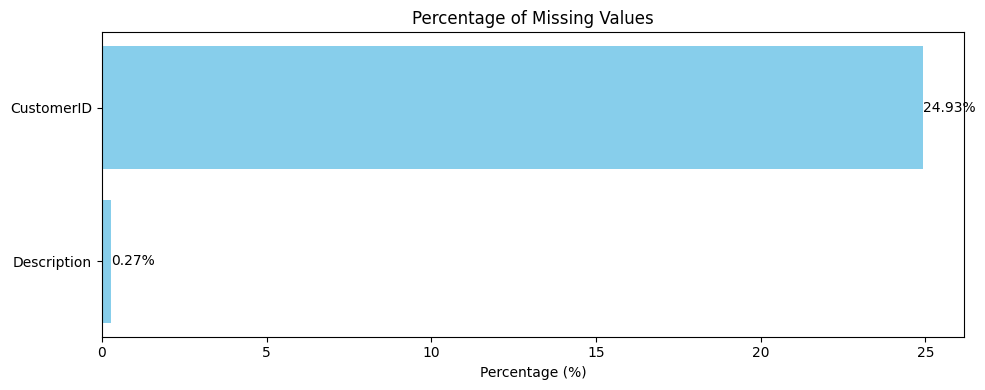

In [8]:
# Calculate missing percentage (same as before)
missing_data = df.isnull().sum()
missing_percentage = (missing_data[missing_data > 0] / df.shape[0]) * 100
missing_percentage.sort_values(ascending=True, inplace=True)

# Simple horizontal bar plot
plt.figure(figsize=(10,4))
bars = plt.barh(missing_percentage.index, missing_percentage, color='skyblue')

# Add percentage labels to each bar
for index, value in enumerate(missing_percentage):
    plt.text(value + 0.01
             ,  # a little to the right of the bar
             index,        # y-position of the bar
             f'{value:.2f}%',
             va='center',
             fontsize=10)

plt.title('Percentage of Missing Values')
plt.xlabel('Percentage (%)')
plt.tight_layout()
plt.show()

**Handling Missing Values Strategy:**

Since CustomerID had around 25% missing values and is essential for clustering and recommendation, I removed those rows instead of imputing them to avoid introducing noise. The Description column had very few missing values (0.27%), but because product descriptions were inconsistent for the same StockCode, I also chose to drop those rows instead of filling them. Removing these missing entries allowed me to maintain data reliability and build cleaner customer profiles for accurate clustering.

In [9]:
# Extracting rows with missing values in 'CustomerID' or 'Description' columns
df[df['CustomerID'].isnull() | df['Description'].isnull()].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,12/1/2010 11:52,0.00,NaN,United Kingdom
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,12/1/2010 14:32,2.51,NaN,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,12/1/2010 14:32,2.51,NaN,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,12/1/2010 14:32,0.85,NaN,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,12/1/2010 14:32,1.66,NaN,United Kingdom


In [10]:
# Removing rows with missing values in 'CustomerID' and 'Description' columns
df = df.dropna(subset=['CustomerID', 'Description'])

In [11]:
# Verifying the removal of missing values
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

### Handling Duplicates

In [12]:
# Finding duplicate rows (keeping all instances)
duplicate_rows = df[df.duplicated(keep=False)]

# Sorting the data by certain columns to see the duplicate rows next to each other
duplicate_rows_sorted = duplicate_rows.sort_values(by=['InvoiceNo','StockCode','Description','CustomerID','Quantity'])

# Displaying the first 10 records
duplicate_rows_sorted.head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,12/1/2010 11:45,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,12/1/2010 11:45,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,12/1/2010 11:45,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,12/1/2010 11:45,2.95,17908.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,12/1/2010 11:49,1.65,17920.0,United Kingdom
598,536412,21448,12 DAISY PEGS IN WOOD BOX,1,12/1/2010 11:49,1.65,17920.0,United Kingdom


**Handling Duplicates Strategy:**

In the context of this project, the presence of completely identical rows, including identical transaction times, suggests that these might be data recording errors rather than genuine repeated transactions. Keeping these duplicate rows can introduce noise and potential inaccuracies in the clustering and recommendation system.

Therefore, I am going to remove these completely identical duplicate rows from the dataset. Removing these rows will help in achieving a cleaner dataset, which in turn would aid in building more accurate customer clusters based on their unique purchasing behaviors. Moreover, it would help in creating a more precise recommendation system by correctly identifying the products with the most purchases.

In [13]:
# Displaying the number of duplicate rows
print(f"The dataset contains {df.duplicated().sum()} duplicate rows that need to be removed.")

# Removing duplicate rows
df.drop_duplicates(inplace=True)

The dataset contains 5225 duplicate rows that need to be removed.


In [14]:
# Getting the number of rows in the dataframe
df.shape[0]

401604

### Treating Cancelled Transactions

In [15]:
# Create boolean masks for negative Quantity and 'C' prefix in InvoiceNo
is_negative_qty = df['Quantity'] < 0
has_c_prefix = df['InvoiceNo'].astype(str).str.startswith('C')

# 1. Check if ALL negative quantities have a 'C' prefix
neg_has_c = (is_negative_qty == has_c_prefix).all()

# 2. See the exact breakdown of matches and mismatches
mismatches = df[is_negative_qty != has_c_prefix]

print(f"Do negative quantities strictly match the 'C' prefix? {neg_has_c}")
print(f"Total mismatch rows: {len(mismatches)}")

# Inspect mismatches if any exist
if not mismatches.empty:
    print(mismatches[['InvoiceNo', 'Quantity']].head())

Do negative quantities strictly match the 'C' prefix? True
Total mismatch rows: 0


In [16]:
# Filter out the rows with InvoiceNo starting with "C" and create a new column indicating the transaction status
df['Transaction_Status'] = np.where(df['InvoiceNo'].astype(str).str.startswith('C'),'Cancelled','Completed')

# Analyze the characteritics of these rows (considering the new column)
cancelled_transactions = df[df['Transaction_Status'] == 'Cancelled']
cancelled_transactions.describe().drop('CustomerID', axis=1)

,Quantity,UnitPrice
count,8872.000000,8872.000000
mean,-30.774910,18.899512
std,1172.249902,445.190864
min,-80995.000000,0.010000
25%,-6.000000,1.450000
50%,-2.000000,2.950000
75%,-1.000000,4.950000
max,-1.000000,38970.000000


**Inferences from the Cancelled Transactions Data:**

Cancelled transactions had negative quantities and a wide range of unit prices, confirming that they represent valid returns. Instead of removing them, I kept them and marked them separately, because cancellation behavior is also an important part of customer behavior. Including this information helps clustering capture risky or inconsistent customers and prevents the recommendation system from suggesting products that are frequently cancelled.

In [17]:
# Share of cancelled line items (rows) at this stage,
# BEFORE non-product stock codes and zero prices are removed
cancelled_percentage = (cancelled_transactions.shape[0] / df.shape[0]) * 100

print(f"Cancelled line items make up {cancelled_percentage:.2f}% of all rows at this stage "
      f"(before removing non-product stock codes).")

Cancelled line items make up 2.21% of all rows at this stage (before removing non-product stock codes).


### Correcting StockCode Anomalies

In [18]:
# Finding the number of unique stock codes
unique_stock_codes = df['StockCode'].nunique()

# Printing the number of unique stock codes
print(f"The number of unique stock codes in the dataset is: {unique_stock_codes}")

The number of unique stock codes in the dataset is: 3684


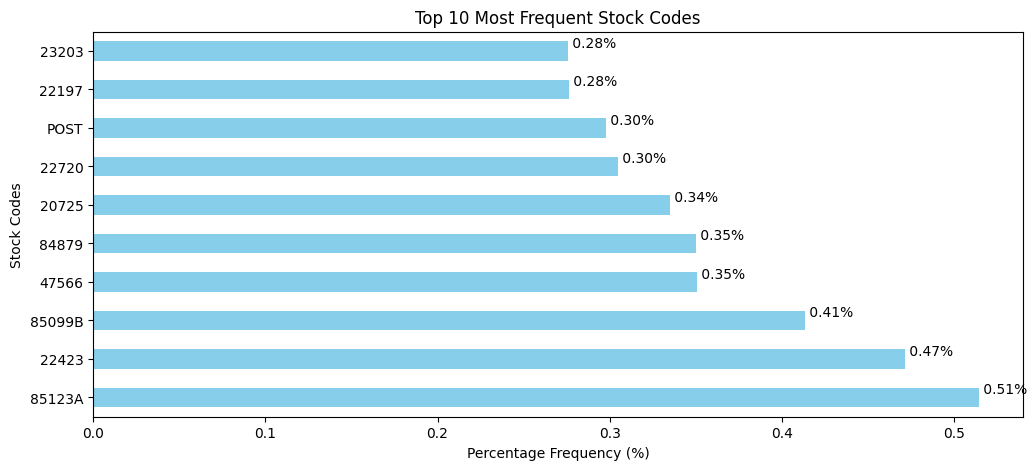

In [19]:
# Finding the top 10 most frequent stock codes
top_10_stock_codes = df['StockCode'].value_counts(normalize=True).head(10) * 100

# Plotting the top 10 most frequent stock codes
plt.figure(figsize=(12,5))
top_10_stock_codes.plot(kind='barh', color='skyblue')

# Adding the percentage frequency on the bars
for index, value in enumerate(top_10_stock_codes):
  plt.text(value, index+0.1, f'{value: .2f}%', fontsize=10)

plt.title('Top 10 Most Frequent Stock Codes')
plt.xlabel('Percentage Frequency (%)')
plt.ylabel('Stock Codes')
plt.show()

**Inferences on Stock Codes:**

Product Variety: The dataset contains 3684 unique stock codes, indicating a substantial variety of products available in the online retail store. This diversity can potentially lead to the identification of distinct customer clusters, with preferences for different types of products.

Popular Items: A closer look at the top 10 most frequent stock codes can offer insights into the popular products or categories that are frequently purchased by customers.

Stock Code Anomalies: We observe that while most stock codes are composed of 5 or 6 characters, there are some anomalies like the code 'POST'. These anomalies might represent services or non-product transactions (perhaps postage fees) rather than actual products. To maintain the focus of the project, which is clustering based on product purchases and creating a recommendation system, these anomalies should be further investigated and possibly treated appropriately to ensure data integrity.

In [20]:
# Finding the number of numeric characters in each unique stock code
unique_stock_codes = df['StockCode'].unique()
numeric_char_counts_in_unique_codes = pd.Series(unique_stock_codes).apply(lambda x: sum(c.isdigit() for c in str(x))).value_counts()

# Printing the value counts for unique stock codes
print("Value counts of numeric character frequencies in unique stock codes:")
print("-"*70)
print(numeric_char_counts_in_unique_codes)

Value counts of numeric character frequencies in unique stock codes:
----------------------------------------------------------------------
5    3676
0       7
1       1
Name: count, dtype: int64


**Inference:**

The output indicates the following:

A majority of the unique stock codes (3676 out of 3684) contain exactly 5 numeric characters, which seems to be the standard format for representing product codes in this dataset.

There are a few anomalies: 7 stock codes contain no numeric characters and 1 stock code contains only 1 numeric character. These are clearly deviating from the standard format and need further investigation to understand their nature and whether they represent valid product transactions.

In [21]:
# Finding and printing the stock codes with 0 and 1 numeric characters
anomalous_stock_codes = [code for code in unique_stock_codes if sum(c.isdigit() for c in str(code)) in (0,1)]

# Printing each stock code on a new line
print("Anomalous stock codes:")
print("-"*22)
for code in anomalous_stock_codes:
  print(code)

Anomalous stock codes:
----------------------
POST
D
C2
M
BANK CHARGES
PADS
DOT
CRUK


In [22]:
# Calculating the percentage of records with these stock codes
percentage_anomalous = (df['StockCode'].isin(anomalous_stock_codes).sum() / len(df)) * 100

# Printing the percentage
print(f"The percentage of records with anomalous stock codes in the dataset is: {percentage_anomalous: .2f}%")


The percentage of records with anomalous stock codes in the dataset is:  0.48%


**Inference:**

Based on the analysis, we find that a very small proportion of the records, 0.48%, have anomalous stock codes, which deviate from the typical format observed in the majority of the data. Also, these anomalous codes are just a fraction among all unique stock codes (only 8 out of 3684).

These codes seem to represent non-product transactions like "BANK CHARGES", "POST" (possibly postage fees), etc. Since they do not represent actual products and are a very small proportion of the dataset, including them in the analysis might introduce noise and distort the clustering and recommendation system.

In [23]:
# Removing rows with anomalous stock codes from the dataset
df = df[~df['StockCode'].isin(anomalous_stock_codes)]

In [24]:
# Getting the number of rows in the dataframe
df.shape[0]

399689

### Cleaning Description Column

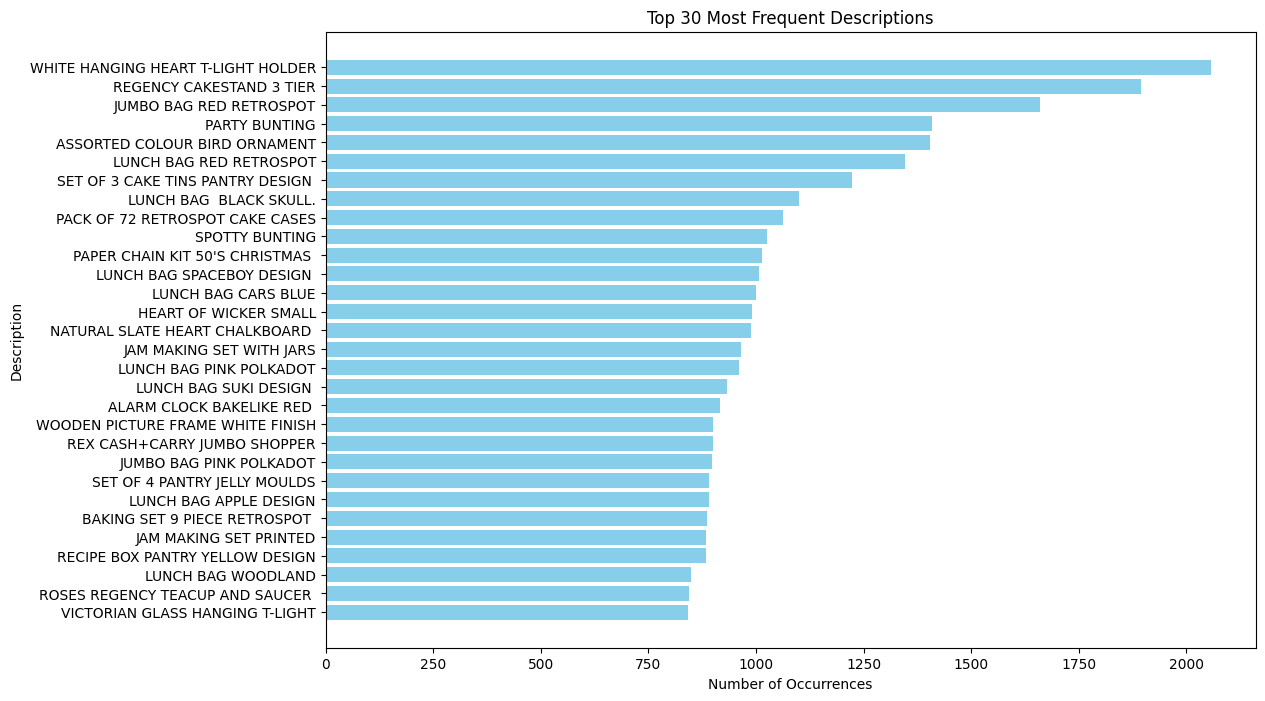

In [25]:
# Calculate the occurrence of each unique description and sort them
description_counts = df['Description'].value_counts()

# Get the top 30 descriptions
top_30_descriptions = description_counts[:30]

# Plotting
plt.figure(figsize=(12,8))
plt.barh(top_30_descriptions.index[::-1], top_30_descriptions.values[::-1], color='skyblue')

# Adding labels and title
plt.xlabel('Number of Occurrences')
plt.ylabel('Description')
plt.title('Top 30 Most Frequent Descriptions')
plt.show()

**Inferences on Descriptions:**

The most frequent descriptions are generally household items, particularly those associated with kitchenware, lunch bags, and decorative items.

Interestingly, all the descriptions are in uppercase, which might be a standardized format for entering product descriptions in the database. However, considering the inconsistencies and anomalies encountered in the dataset so far, it would be prudent to check if there are descriptions entered in lowercase or a mix of case styles.

In [26]:
# Find unique descriptions containing lowercase characters
lowercase_descriptions = df['Description'].unique()
lowercase_descriptions = [desc for desc in lowercase_descriptions if any(char.islower() for char in desc)]

# Print the unique descriptions containing lowercase characters
print("The unique descriptions containing lowercase characters are:")
print("-"*60)
for desc in lowercase_descriptions:
  print(desc)

The unique descriptions containing lowercase characters are:
------------------------------------------------------------
BAG 500g SWIRLY MARBLES
POLYESTER FILLER PAD 45x45cm
POLYESTER FILLER PAD 45x30cm
POLYESTER FILLER PAD 40x40cm
FRENCH BLUE METAL DOOR SIGN No
BAG 250g SWIRLY MARBLES
BAG 125g SWIRLY MARBLES
3 TRADITIONAl BISCUIT CUTTERS  SET
NUMBER TILE COTTAGE GARDEN No
FOLK ART GREETING CARD,pack/12
ESSENTIAL BALM 3.5g TIN IN ENVELOPE
POLYESTER FILLER PAD 65CMx65CM
NUMBER TILE VINTAGE FONT No 
POLYESTER FILLER PAD 30CMx30CM
POLYESTER FILLER PAD 60x40cm
FLOWERS HANDBAG blue and orange
Next Day Carriage
THE KING GIFT BAG 25x24x12cm
High Resolution Image


**Inference:**

Upon reviewing the descriptions that contain lowercase characters, it is evident that some entries are not product descriptions, such as "Next Day Carriage" and "High Resolution Image". These entries seem to be unrelated to the actual products and might represent other types of information or service details.

**Strategy:**

Step 1: Remove the rows where the descriptions contain service-related information like "Next Day Carriage" and "High Resolution Image", as these do not represent actual products and would not contribute to the clustering and recommendation system we aim to build.

Step 2: For the remaining descriptions with mixed case, standardize the text to uppercase to maintain uniformity across the dataset. This will also assist in reducing the chances of having duplicate entries with different case styles.

In [27]:
service_related_descriptions = ['Next Day Carriage', 'High Resolution Image']

# Calculate the percentage of records with service-related descriptions
service_related_percentage = df[df['Description'].isin(service_related_descriptions)].shape[0] / df.shape[0] * 100

# Print the percentage of records with service-related desrciptions
print(f'The percentage of records with service-related descriptions in the dataset is: {service_related_percentage: .2f}%')

# Remove rows with service-related information in the description
df = df[~df['Description'].isin(service_related_descriptions)]

# Standardize the text to uppercase to maintain uniformly across the dataset
df['Description'] = df['Description'].str.upper()

The percentage of records with service-related descriptions in the dataset is:  0.02%


In [28]:
df.shape[0]

399606

### Treating Zero Unit Prices

In [29]:
df['UnitPrice'].describe()

count    399606.000000
mean          2.904957
std           4.448796
min           0.000000
25%           1.250000
50%           1.950000
75%           3.750000
max         649.500000
Name: UnitPrice, dtype: float64

**Inference:**

The minimum unit price value is zero. This suggests that there are some transactions where the unit price is zero, potentially indicating a free item or a data entry error. To understand their nature, it is essential to investigate these zero unit price transactions further. A detailed analysis of the product descriptions associated with zero unit prices will be conducted to determine if they adhere to a specific pattern:

In [30]:
df[df['UnitPrice']==0].describe()[['Quantity']]

,Quantity
count,33.000000
mean,420.515152
std,2176.713608
min,1.000000
25%,2.000000
50%,11.000000
75%,36.000000
max,12540.000000


**Inferences on UnitPrice:**

The transactions with a unit price of zero are relatively few in number (33 transactions).

These transactions have a large variability in the quantity of items involved, ranging from 1 to 12540, with a substantial standard deviation.

Including these transactions in the clustering analysis might introduce noise and could potentially distort the customer behavior patterns identified by the clustering algorithm.

**Strategy:**

Given the small number of these transactions and their potential to introduce noise in the data analysis, the strategy should be to remove these transactions from the dataset. This would help in maintaining a cleaner and more consistent dataset, which is essential for building an accurate and reliable clustering model and recommendation system.

In [31]:
# Removing records with a unit price of zero to avoid potential data entry errors
df = df[df['UnitPrice'] > 0]

### Outlier Treatment
In K-means clustering, the algorithm is sensitive to both the scale of data and the presence of outliers, as they can significantly influence the position of centroids, potentially leading to incorrect cluster assignments. However, considering the context of this project where the final goal is to understand customer behavior and preferences through K-means clustering, it would be more prudent to address the issue of outliers after the feature engineering phase where we create a customer-centric dataset. At this stage, the data is transactional, and removing outliers might eliminate valuable information that could play a crucial role in segmenting customers later on. Therefore, we will postpone the outlier treatment and proceed to the next stage for now.

In [32]:
# Resetting the index of the cleaned dataset
df.reset_index(drop=True, inplace=True)

In [33]:
# Getting the number of rows in the dataframe
df.shape[0]

399573

In [34]:
# Cancellation share on the FINAL cleaned data
cancelled_rows = df['Transaction_Status'] == 'Cancelled'

print(f"Cancelled line items: {cancelled_rows.mean() * 100:.2f}% of all rows")
print(f"Cancelled invoices:   {df.loc[cancelled_rows, 'InvoiceNo'].nunique() / df['InvoiceNo'].nunique() * 100:.2f}% of all invoices")
print(df.loc[cancelled_rows, ['Quantity', 'UnitPrice']].describe().round(2))

Cancelled line items: 2.13% of all rows
Cancelled invoices:   15.53% of all invoices
       Quantity  UnitPrice
count   8505.00    8505.00
mean     -31.48       4.44
std     1197.12       9.20
min   -80995.00       0.03
25%       -6.00       1.45
50%       -2.00       2.55
75%       -1.00       4.95
max       -1.00     295.00


**Inference:**
After cleaning, cancelled orders make up [X]% of all line items and [Y]% of all invoices. The earlier figure was measured before removing non-product stock codes and zero-price rows, so it is a share of rows at that stage, not of the final dataset.

# Feature Engineering

RFM is a method used for analyzing customer value and segmenting the customer base. It is an acronym that stands for:

**Recency (R):** This metric indicates how recently a customer has made a purchase. A lower recency value means the customer has purchased more recently, indicating higher engagement with the brand.

**Frequency (F):** This metric signifies how often a customer makes a purchase within a certain period. A higher frequency value indicates a customer who interacts with the business more often, suggesting higher loyalty or satisfaction.

**Monetary (M):** This metric represents the total amount of money a customer has spent over a certain period. Customers who have a higher monetary value have contributed more to the business, indicating their potential high lifetime value.

### Recency (R):
**Days Since Last Purchase:** This feature measures how many days have passed since the customer’s last purchase. Lower values mean active customers, while higher values indicate inactivity. It helps identify customers who may need re-engagement strategies to improve retention and loyalty

In [35]:
# Convert InvoiceDate to datatime type
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Convert InvoiceDate to datetime and extract only the date
df['InvoiceDay'] = df['InvoiceDate'].dt.date

# Find the most recent purchase date for each customer
customer_data = df.groupby('CustomerID')['InvoiceDay'].max().reset_index()

# Find the most recent date in the entire dataset
most_recent_date = df['InvoiceDay'].max()

# Convert InvoiceDay to datetime type before subtraction
customer_data['InvoiceDay'] = pd.to_datetime(customer_data['InvoiceDay'])
most_recent_date = pd.to_datetime(most_recent_date)

# Calculate the number of days since the last purchase for each customer
customer_data['Days_Since_Last_Purchase'] = (most_recent_date - customer_data['InvoiceDay']).dt.days

# Remove the InvoiceDay column
customer_data.drop(columns=['InvoiceDay'],inplace=True)

In [36]:
customer_data.head()

,CustomerID,Days_Since_Last_Purchase
0,12346.0,325
1,12347.0,2
2,12348.0,75
3,12349.0,18
4,12350.0,310


### Frequency (F)
**Total Transactions:** This feature represents the total number of transactions made by a customer. It helps in understanding the engagement level of a customer with the retailer.

**Total Products Purchased:** This feature indicates the total number of products (sum of quantities) purchased by a customer across all transactions. It gives an insight into the customer's buying behavior in terms of the volume of products purchased

In [37]:
# Calculate the total number of transactions made by each customer
total_transactions = df.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()
total_transactions.rename(columns={'InvoiceNo': 'Total_Transactions'}, inplace=True)

# Calculate the total number of products purchased by each customer
total_products_purchased = df.groupby('CustomerID')['Quantity'].sum().reset_index()
total_products_purchased.rename(columns={'Quantity': 'Total_Products_Purchased'}, inplace=True)

# Merge the new features into the customer_data dataframe
customer_data = pd.merge(customer_data, total_transactions, on='CustomerID')
customer_data = pd.merge(customer_data, total_products_purchased, on='CustomerID')

customer_data.head()

,CustomerID,Days_Since_Last_Purchase,Total_Transactions,Total_Products_Purchased
0,12346.0,325,2,0
1,12347.0,2,7,2458
2,12348.0,75,4,2332
3,12349.0,18,1,630
4,12350.0,310,1,196


### Monetary (M)
**Total Spend:** This feature represents the total amount of money spent by each customer. It is calculated as the sum of the product of UnitPrice and Quantity for all transactions made by a customer. This feature is crucial as it helps in identifying the total revenue generated by each customer, which is a direct indicator of a customer's value to the business.

**Average Transaction Value:** This feature is calculated as the Total Spend divided by the Total Transactions for each customer. It indicates the average value of a transaction carried out by a customer. This metric is useful in understanding the spending behavior of customers per transaction, which can assist in tailoring marketing strategies and offers to different customer segments based on their average spending patterns.

In [38]:
# Calculate the total spend by each customer
df['Total_Spend'] = df['UnitPrice']*df['Quantity']
total_spend = df.groupby('CustomerID')['Total_Spend'].sum().reset_index()

# Calculate the average transaction value for each customer
average_transaction_value = total_spend.merge(total_transactions,on='CustomerID')
average_transaction_value['Average_Transaction_Value'] = average_transaction_value['Total_Spend'] / average_transaction_value['Total_Transactions']

# Merge the new features into the customer_data dataframe
customer_data = pd.merge(customer_data, total_spend, on='CustomerID')
customer_data = pd.merge(customer_data, average_transaction_value[['CustomerID','Average_Transaction_Value']], on='CustomerID')

customer_data.head()

,CustomerID,Days_Since_Last_Purchase,Total_Transactions,Total_Products_Purchased,Total_Spend,Average_Transaction_Value
0,12346.0,325,2,0,0.00,0.000000
1,12347.0,2,7,2458,4310.00,615.714286
2,12348.0,75,4,2332,1437.24,359.310000
3,12349.0,18,1,630,1457.55,1457.550000
4,12350.0,310,1,196,294.40,294.400000


### Product Diversity
**Unique Products Purchased:** This feature represents the number of distinct products bought by a customer. A higher value indicates that the customer has a diverse taste or preference, buying a wide range of products, while a lower value might indicate a focused or specific preference. Understanding the diversity in product purchases can help in segmenting customers based on their buying diversity, which can be a critical input in personalizing product recommendations

In [39]:
# Calculate the number of unique products purchased by each customer
unique_products_purchased = df.groupby('CustomerID')['StockCode'].nunique().reset_index()
unique_products_purchased.rename(columns={'StockCode':'Unique_Products_Purchased'}, inplace=True)

# Merge the new feature into the customer_data dataframe
customer_data = pd.merge(customer_data, unique_products_purchased, on='CustomerID')

customer_data.head()

,CustomerID,Days_Since_Last_Purchase,Total_Transactions,Total_Products_Purchased,Total_Spend,Average_Transaction_Value,Unique_Products_Purchased
0,12346.0,325,2,0,0.00,0.000000,1
1,12347.0,2,7,2458,4310.00,615.714286,103
2,12348.0,75,4,2332,1437.24,359.310000,21
3,12349.0,18,1,630,1457.55,1457.550000,72
4,12350.0,310,1,196,294.40,294.400000,16


## Cancellation Insights
**Cancellation Frequency:** This metric represents the total number of transactions a customer has canceled. Understanding the frequency of cancellations can help us identify customers who are more likely to cancel transactions. This could be an indicator of dissatisfaction or other issues, and understanding this can help us tailor strategies to reduce cancellations and enhance customer satisfaction.

**Cancellation Rate:** This represents the proportion of transactions that a customer has canceled out of all their transactions. This metric gives a normalized view of cancellation behavior. A high cancellation rate might be indicative of an unsatisfied customer segment. By identifying these segments, we can develop targeted strategies to improve their shopping experience and potentially reduce the cancellation rate.

In [40]:
# Calculate the total number of transactions made by each customer
total_transactions_map = df.groupby('CustomerID')['InvoiceNo'].nunique()

# Calculate the number of cancelled transactions for each customer
cancelled_transactions = df[df['Transaction_Status'] == 'Cancelled']
cancellation_frequency = cancelled_transactions.groupby('CustomerID')['InvoiceNo'].nunique().reset_index()
cancellation_frequency.rename(columns={'InvoiceNo': 'Cancellation_Frequency'}, inplace=True)

# Merge the Cancellation Frequency data into the customer_data dataframe
customer_data = pd.merge(customer_data, cancellation_frequency, on='CustomerID', how='left')

# Replace NaN values with 0 (for customers who have not cancelled any transaction)
customer_data['Cancellation_Frequency'] = customer_data['Cancellation_Frequency'].fillna(0)

# Cancellation Rate = cancelled invoices / all invoices, matched by CustomerID
customer_data['Cancellation_Rate'] = (customer_data['Cancellation_Frequency']
                                      / customer_data['CustomerID'].map(total_transactions_map))

customer_data.head()

,CustomerID,Days_Since_Last_Purchase,Total_Transactions,Total_Products_Purchased,Total_Spend,Average_Transaction_Value,Unique_Products_Purchased,Cancellation_Frequency,Cancellation_Rate
0,12346.0,325,2,0,0.00,0.000000,1,1.0,0.5
1,12347.0,2,7,2458,4310.00,615.714286,103,0.0,0.0
2,12348.0,75,4,2332,1437.24,359.310000,21,0.0,0.0
3,12349.0,18,1,630,1457.55,1457.550000,72,0.0,0.0
4,12350.0,310,1,196,294.40,294.400000,16,0.0,0.0


In [41]:
customer_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4362 entries, 0 to 4361
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   CustomerID                 4362 non-null   float64
 1   Days_Since_Last_Purchase   4362 non-null   int64  
 2   Total_Transactions         4362 non-null   int64  
 3   Total_Products_Purchased   4362 non-null   int64  
 4   Total_Spend                4362 non-null   float64
 5   Average_Transaction_Value  4362 non-null   float64
 6   Unique_Products_Purchased  4362 non-null   int64  
 7   Cancellation_Frequency     4362 non-null   float64
 8   Cancellation_Rate          4362 non-null   float64
dtypes: float64(5), int64(4)
memory usage: 306.8 KB


In [42]:
neg = customer_data[customer_data['Total_Spend'] <= 0]
print(len(neg))
print((neg['Total_Transactions'] == neg['Cancellation_Frequency']).sum())
neg.head(10)

38
28


,CustomerID,Days_Since_Last_Purchase,Total_Transactions,Total_Products_Purchased,Total_Spend,Average_Transaction_Value,Unique_Products_Purchased,Cancellation_Frequency,Cancellation_Rate
0,12346.0,325,2,0,0.00,0.00,1,1.0,0.5
210,12605.0,365,1,-4,-7.50,-7.50,3,1.0,1.0
262,12666.0,359,1,-56,-227.44,-227.44,2,1.0,1.0
413,12870.0,366,1,-2,-14.90,-14.90,2,1.0,1.0
465,12943.0,301,1,-1,-3.75,-3.75,1,1.0,1.0
771,13364.0,66,2,0,0.00,0.00,10,1.0,0.5
987,13672.0,301,5,0,0.00,0.00,4,3.0,0.6
1000,13693.0,325,2,-6,-32.00,-16.00,4,2.0,1.0
1102,13829.0,359,1,-12,-102.00,-102.00,1,1.0,1.0
1196,13958.0,372,1,-23,-102.45,-102.45,5,1.0,1.0


**Inference:**
Customers with a total spend of zero or less have no actual commercial purchase history—representing only administrative anomalies, freebies, or pure cancellations—which adds invalid noise to behavioral clustering.

I Identified and dropped these 38 accounts, successfully streamlining the dataset down to 4,324 valid customer profiles.

In [43]:
customer_data = customer_data[customer_data['Total_Spend'] > 0].reset_index(drop=True)
print(customer_data.shape)      # expect 4,324 rows (4,362 - 38)

(4324, 9)


In [44]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])      # safe to run again if it is already datetime

completed = df[df['Transaction_Status'] == 'Completed'].copy()
completed['InvoiceDay'] = completed['InvoiceDate'].dt.normalize()
most_recent = df['InvoiceDate'].dt.normalize().max()

recency   = (most_recent - completed.groupby('CustomerID')['InvoiceDay'].max()).dt.days
frequency = completed.groupby('CustomerID')['InvoiceNo'].nunique()

customer_data['Days_Since_Last_Purchase'] = customer_data['CustomerID'].map(recency)
customer_data['Total_Transactions']       = customer_data['CustomerID'].map(frequency)

print(customer_data[['Days_Since_Last_Purchase', 'Total_Transactions']].isna().sum())   # expect 0 and 0

Days_Since_Last_Purchase    0
Total_Transactions          0
dtype: int64


Feature definitions used in the clustering:
- Days_Since_Last_Purchase and Total_Transactions: completed orders only.
- Total_Spend and Total_Products_Purchased: net of returns (cancelled lines are subtracted).
- Average_Transaction_Value: Total_Spend divided by all invoices (completed and cancelled).
- Unique_Products_Purchased: distinct stock codes across all of the customer's lines, including cancelled ones.
- Cancellation_Rate: cancelled invoices divided by all invoices.

### Reducing Skew with a Log Transform
Extreme customers are real high-value buyers, not errors, so I did not delete them. Instead I reduced their influence with a log1p transform. Skew fell strongly for Total_Spend (21.55 to 0.21) and Total_Products_Purchased (22.93 to about 0). Total_Transactions (1.21) and Cancellation_Frequency (1.67) stay somewhat right-skewed because most customers place only a few orders, and Cancellation_Rate (1.47) was left unchanged because it is already a proportion. I removed 38 customers with zero or negative spend because they have no purchase behaviour.

Negative values per column:
Days_Since_Last_Purchase     0
Total_Transactions           0
Total_Products_Purchased     0
Total_Spend                  0
Average_Transaction_Value    0
Unique_Products_Purchased    0
Cancellation_Frequency       0
Cancellation_Rate            0
dtype: int64
                           skew_before  skew_after
Days_Since_Last_Purchase          1.25       -0.46
Total_Transactions               11.94        1.21
Total_Products_Purchased         22.93       -0.02
Total_Spend                      21.55        0.21
Average_Transaction_Value         8.87       -0.39
Unique_Products_Purchased         6.92       -0.24
Cancellation_Frequency            9.18        1.67
Cancellation_Rate                 1.47        1.47


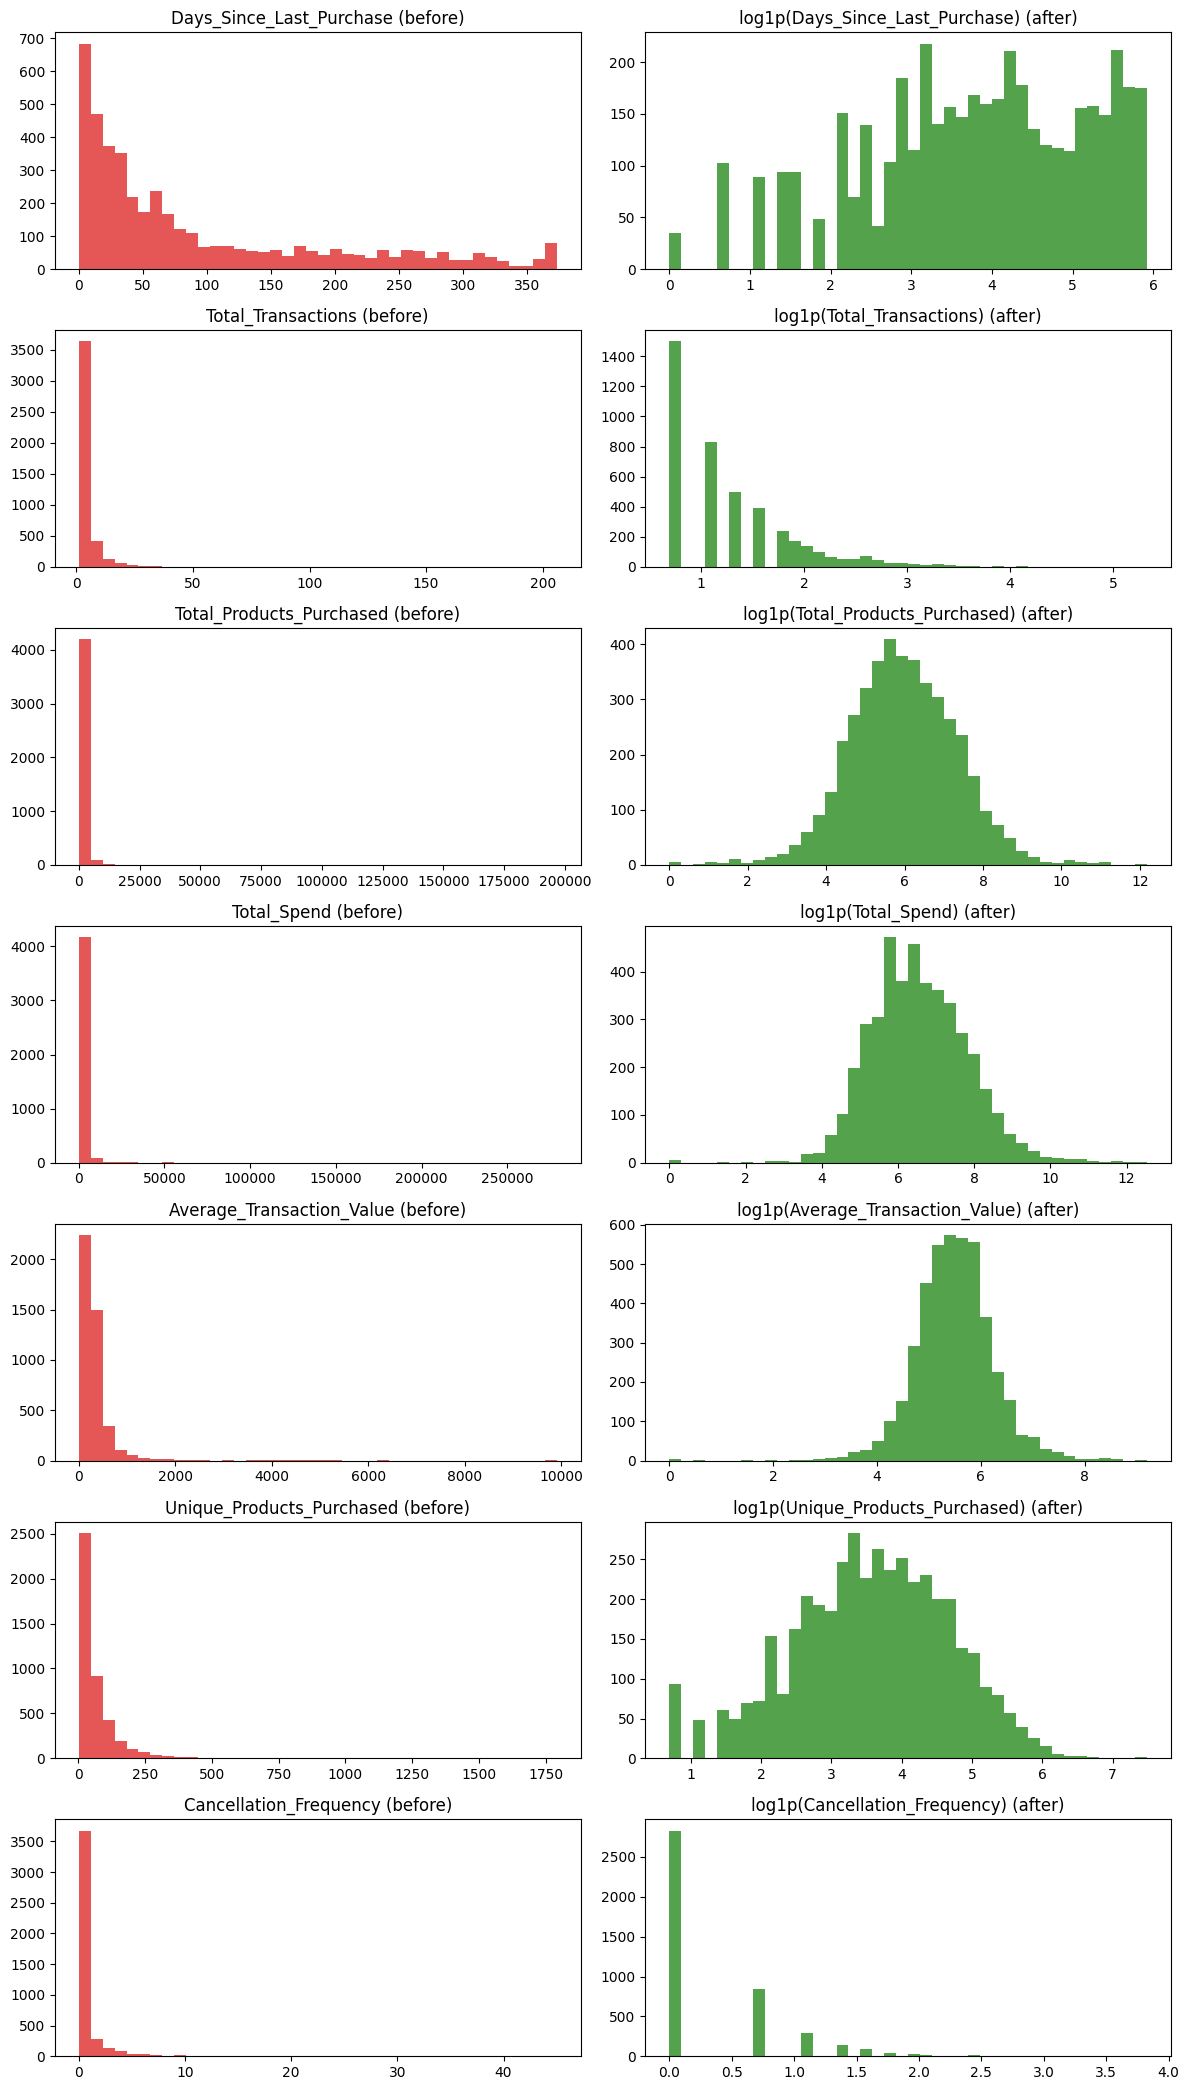

In [45]:
# Columns that are counts or amounts and heavily right-skewed -> log transform
skewed_cols = ['Days_Since_Last_Purchase', 'Total_Transactions', 'Total_Products_Purchased',
               'Total_Spend', 'Average_Transaction_Value', 'Unique_Products_Purchased',
               'Cancellation_Frequency']
# Cancellation_Rate is already a proportion between 0 and 1, so it is left as it is
all_cols = skewed_cols + ['Cancellation_Rate']

# Skewness BEFORE
skew_before = customer_data[all_cols].skew()

# log1p cannot handle values below -1, so check for negatives first
print("Negative values per column:")
print((customer_data[all_cols] < 0).sum())

# Transform: clip at 0, then log1p. Keep the original dataframe untouched
customer_log = customer_data.copy()
for col in skewed_cols:
    customer_log[col] = np.log1p(customer_data[col].clip(lower=0))

# Skewness AFTER
skew_after = customer_log[all_cols].skew()
print(pd.DataFrame({'skew_before': skew_before, 'skew_after': skew_after}).round(2))

# Before / after histograms
fig, axes = plt.subplots(len(skewed_cols), 2, figsize=(12, 3 * len(skewed_cols)))
for i, col in enumerate(skewed_cols):
    axes[i, 0].hist(customer_data[col], bins=40, color='#E45756')
    axes[i, 0].set_title(f'{col} (before)')
    axes[i, 1].hist(customer_log[col], bins=40, color='#54A24B')
    axes[i, 1].set_title(f'log1p({col}) (after)')
plt.tight_layout()
plt.show()

# Data Preprocessing

### Scaling and PCA

The 8 log-transformed features are on very different scales (day counts vs proportions vs currency), so before clustering they are standardized to mean 0 and standard deviation 1. PCA is then applied to reduce these correlated features into a smaller number of components that still capture most of the variation, chosen to keep at least 85% of the original information.

In [46]:
# Scaling (all 8 log-transformed features, CustomerID becomes the index) 
X = customer_log.set_index('CustomerID')[all_cols]
X_scaled = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=all_cols)
print(X_scaled.mean().round(2).tolist())   # all ~0
print(X_scaled.std().round(2).tolist())    # all ~1

[-0.0, -0.0, 0.0, -0.0, 0.0, 0.0, 0.0, -0.0]
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


[0.538 0.746 0.864 0.922 0.974 0.989 1.    1.   ] -> components needed: 3


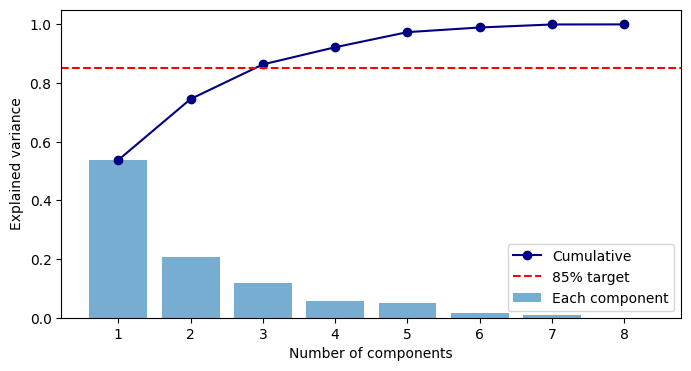

In [47]:
# PCA: how many components keep 85% of the information? 
pca_full = PCA(random_state=42).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.argmax(cum_var >= 0.85) + 1)
print(cum_var.round(3), '-> components needed:', n_components)

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(cum_var) + 1), pca_full.explained_variance_ratio_, alpha=0.6, label='Each component')
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', color='navy', label='Cumulative')
plt.axhline(0.85, color='red', ls='--', label='85% target')
plt.xlabel('Number of components'); plt.ylabel('Explained variance'); plt.legend()
plt.show()

In [48]:
# Final PCA with the chosen number of components 
pca = PCA(n_components=n_components, random_state=42)
X_pca = pd.DataFrame(pca.fit_transform(X_scaled), index=X_scaled.index,
                     columns=[f'PC{i+1}' for i in range(n_components)])
print(X_pca.shape)

(4324, 3)


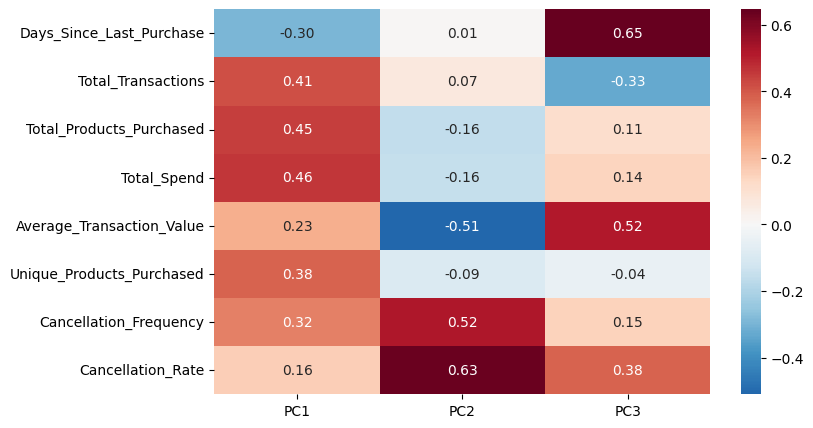

In [49]:
# Loadings: what each component is made of 
loadings = pd.DataFrame(pca.components_.T, index=all_cols, columns=X_pca.columns)
plt.figure(figsize=(8, 5))
sns.heatmap(loadings, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.show()

# Customer Segmentation using KMeans Clustering

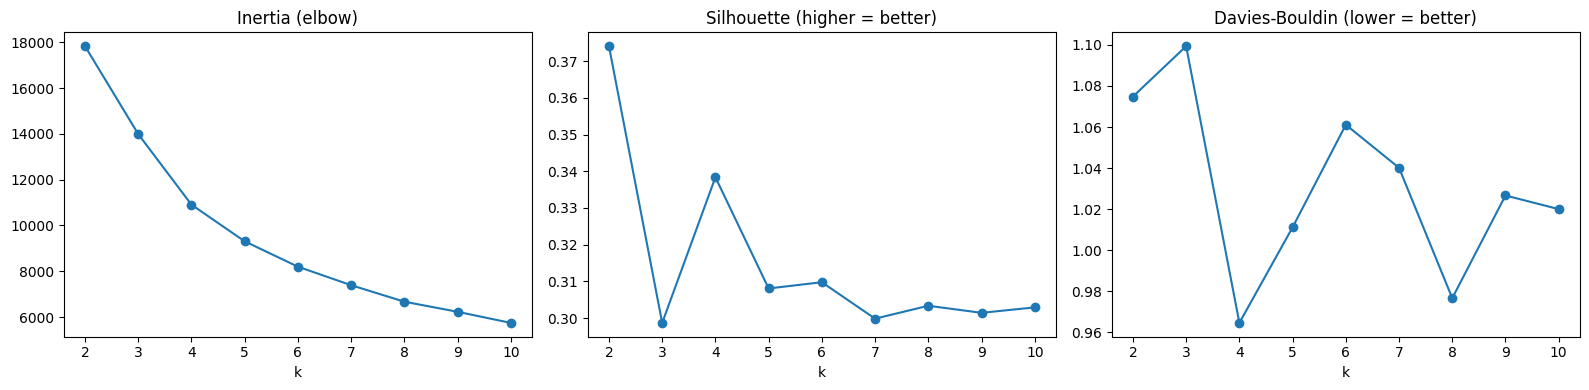

 k   inertia  silhouette  davies_bouldin
 2 17832.746       0.374           1.075
 3 13991.419       0.299           1.099
 4 10907.787       0.338           0.965
 5  9306.858       0.308           1.011
 6  8199.021       0.310           1.061
 7  7390.351       0.300           1.040
 8  6669.302       0.303           0.977
 9  6228.954       0.301           1.027
10  5743.792       0.303           1.020


In [50]:
ks = list(range(2, 11))
inertias, sils, dbs = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(X_pca)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_pca, km.labels_))
    dbs.append(davies_bouldin_score(X_pca, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, vals, title in zip(axes, [inertias, sils, dbs],
                           ['Inertia (elbow)', 'Silhouette (higher = better)', 'Davies-Bouldin (lower = better)']):
    ax.plot(ks, vals, marker='o'); ax.set_title(title); ax.set_xlabel('k')
plt.tight_layout(); plt.show()

print(pd.DataFrame({'k': ks, 'inertia': inertias, 'silhouette': sils, 'davies_bouldin': dbs}).round(3).to_string(index=False))

k = 4 gives the best Davies-Bouldin score (0.965) and the best silhouette (0.338) among sensible options (k = 3 to 6). k = 2 scores higher on silhouette but only separates active from inactive customers, which is too coarse for marketing.

In [51]:
# Final K-means (k = 4) 
K = 4
kmeans = KMeans(n_clusters=K, n_init=50, random_state=42).fit(X_pca)
labels = pd.Series(kmeans.labels_, index=X_pca.index, name='Cluster')

customer_final = customer_data.set_index('CustomerID').join(labels)
order = customer_final.groupby('Cluster')['Total_Spend'].median().sort_values(ascending=False).index
customer_final['Cluster'] = customer_final['Cluster'].map({old: new for new, old in enumerate(order)})   # 0 = highest spend
print(customer_final['Cluster'].value_counts().sort_index())

# Profile each cluster in original units 
profile = customer_final.groupby('Cluster').agg(
    Customers=('Total_Spend', 'size'),
    Recency_median=('Days_Since_Last_Purchase', 'median'),
    Transactions_median=('Total_Transactions', 'median'),
    Products_median=('Total_Products_Purchased', 'median'),
    Spend_median=('Total_Spend', 'median'),
    AvgTxnValue_median=('Average_Transaction_Value', 'median'),
    UniqueProducts_median=('Unique_Products_Purchased', 'median'),
    CancelFreq_mean=('Cancellation_Frequency', 'mean'),
    CancelRate_mean=('Cancellation_Rate', 'mean'),
    Revenue=('Total_Spend', 'sum'))
profile['Customers_%'] = profile['Customers'] / profile['Customers'].sum() * 100
profile['Revenue_%'] = profile['Revenue'] / profile['Revenue'].sum() * 100
display(profile.round(2).T)

Cluster
0     811
1    1368
2     713
3    1432
Name: count, dtype: int64


Cluster,0,1,2,3
Customers,811.00,1368.00,713.00,1432.00
Recency_median,11.00,40.00,67.00,128.00
Transactions_median,9.00,3.00,2.00,1.00
Products_median,1904.00,546.00,353.00,123.00
Spend_median,3167.73,912.56,644.65,225.14
AvgTxnValue_median,300.07,356.01,157.73,168.65
UniqueProducts_median,115.00,49.50,31.00,14.00
CancelFreq_mean,2.78,0.02,1.47,0.01
CancelRate_mean,0.20,0.00,0.37,0.00
Revenue,5562148.26,1812134.40,538323.20,355819.46


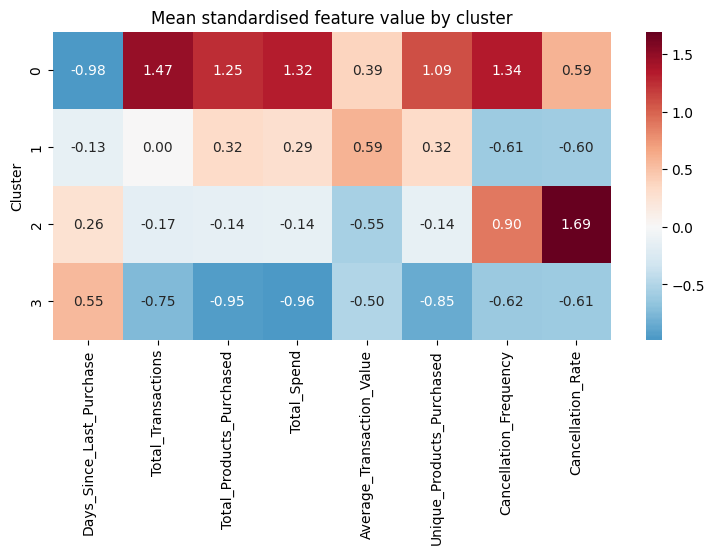

In [52]:
# Heatmap: how each cluster differs from the average customer 
z = X_scaled.join(customer_final['Cluster']).groupby('Cluster').mean()
plt.figure(figsize=(9, 4))
sns.heatmap(z, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Mean standardised feature value by cluster')
plt.show()

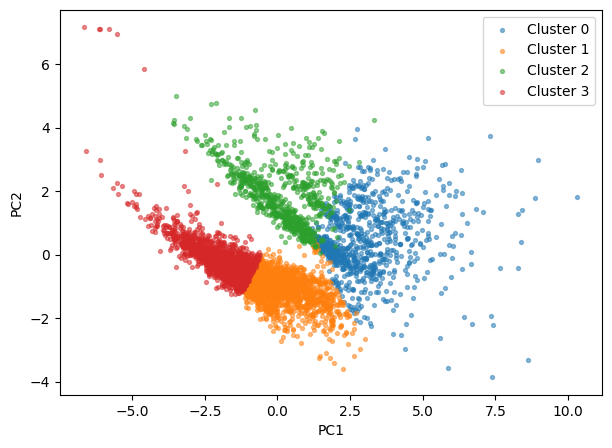

Silhouette: 0.339
Davies-Bouldin: 0.964
Calinski-Harabasz: 2503.6


In [53]:
# Clusters in PCA space 
X_pca['Cluster'] = customer_final.loc[X_pca.index, 'Cluster']
plt.figure(figsize=(7, 5))
for c in range(K):
    m = X_pca['Cluster'] == c
    plt.scatter(X_pca.loc[m, 'PC1'], X_pca.loc[m, 'PC2'], s=8, alpha=0.5, label=f'Cluster {c}')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend(); plt.show()

# Quality scores (compute on PCA columns only, without the Cluster column) 
pcs = X_pca[['PC1', 'PC2', 'PC3']]
print('Silhouette:', round(silhouette_score(pcs, X_pca['Cluster']), 3))
print('Davies-Bouldin:', round(davies_bouldin_score(pcs, X_pca['Cluster']), 3))
print('Calinski-Harabasz:', round(calinski_harabasz_score(pcs, X_pca['Cluster']), 1))

Current overall silhouette: 0.339


,pair,pairwise_silhouette,overall_if_merged,drop_if_merged,centroid_distance
1,0 vs 2,0.378,0.281,0.058,3.435
4,1 vs 3,0.395,0.342,-0.003,2.570
0,0 vs 1,0.442,0.292,0.047,3.238
3,1 vs 2,0.468,0.258,0.081,3.092
5,2 vs 3,0.503,0.249,0.089,3.087
2,0 vs 3,0.642,0.143,0.196,5.213


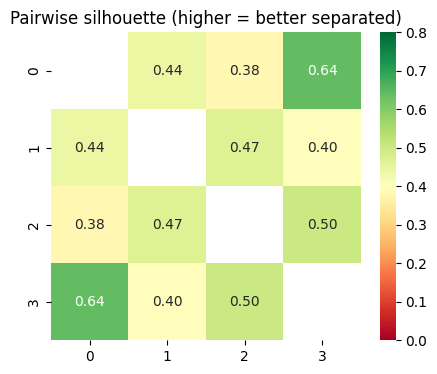

In [54]:
import itertools
pcs = X_pca[['PC1', 'PC2', 'PC3']]
cl = X_pca['Cluster']
overall = silhouette_score(pcs, cl)

rows = []
pair_sil = pd.DataFrame(np.nan, index=range(4), columns=range(4))
for a, b in itertools.combinations(range(4), 2):
    m = cl.isin([a, b])
    s_pair = silhouette_score(pcs[m], cl[m])                       # how well these two separate on their own
    s_merge = silhouette_score(pcs, cl.replace({b: a}))            # overall score if the pair is merged
    dist = np.linalg.norm(pcs[cl == a].mean().values - pcs[cl == b].mean().values)   # distance between centres
    rows.append({'pair': f'{a} vs {b}', 'pairwise_silhouette': s_pair,
                 'overall_if_merged': s_merge, 'drop_if_merged': overall - s_merge,
                 'centroid_distance': dist})
    pair_sil.loc[a, b] = pair_sil.loc[b, a] = s_pair

print('Current overall silhouette:', round(overall, 3))
display(pd.DataFrame(rows).sort_values('pairwise_silhouette').round(3))

plt.figure(figsize=(5, 4))
sns.heatmap(pair_sil.astype(float), annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=0.8)
plt.title('Pairwise silhouette (higher = better separated)')
plt.show()

**Inference:**
The pairwise check shows clusters 0 and 3 are the best separated (silhouette 0.64). Clusters 0 and 2 are the least separated (0.38), and clusters 1 and 3 have the closest centres (2.57 apart). Merging clusters 1 and 3 leaves the overall silhouette essentially unchanged (0.339 to 0.342). I still keep them separate because they differ in recency (40 vs 128 days), order count (3 vs 1) and revenue contribution (21.9% vs 4.3%), which call for different marketing actions.

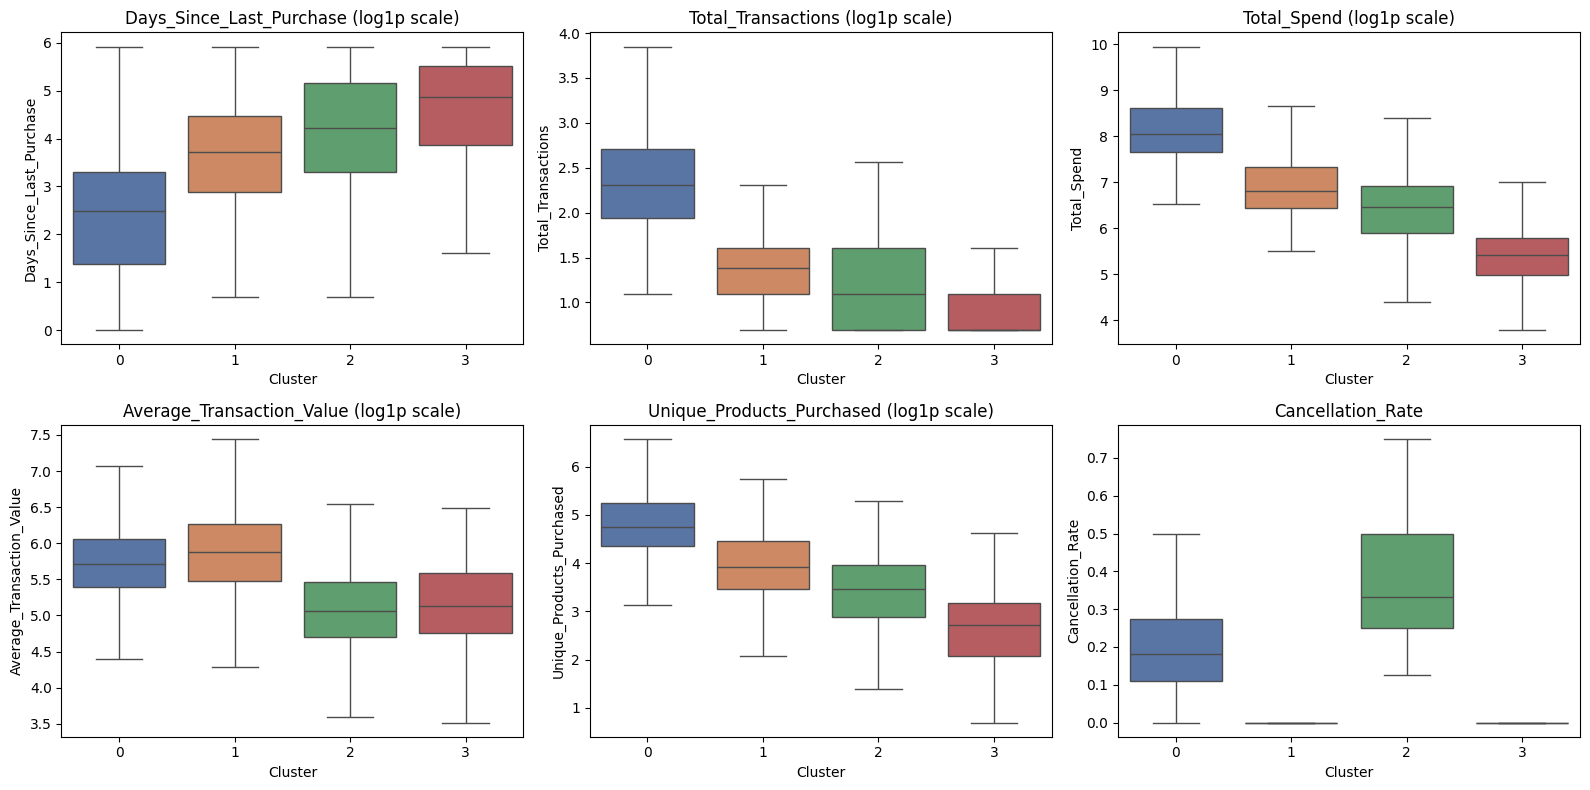

In [55]:
plot_df = customer_log.set_index('CustomerID').join(customer_final['Cluster'])

cols = ['Days_Since_Last_Purchase', 'Total_Transactions', 'Total_Spend',
        'Average_Transaction_Value', 'Unique_Products_Purchased', 'Cancellation_Rate']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.boxplot(data=plot_df, x='Cluster', y=col, hue='Cluster', palette='deep',
                legend=False, showfliers=False, ax=ax)
    ax.set_title(f'{col} (log1p scale)' if col != 'Cancellation_Rate' else col)
plt.tight_layout()
plt.show()

## Cluster Profiles

The customers were segmented into 4 clusters with K-means (k = 4) on 3 PCA components built from 8 log-transformed and standardised behaviour features. Clusters are numbered by median spend (0 = highest). Values below are medians unless stated otherwise. All revenue and customer shares cover identified customers only — about 25% of rows had no CustomerID and were dropped during cleaning.

| | **0 · Champions** | **1 · Reliable Regulars** | **2 · Return-Prone Occasionals** | **3 · Low-Value One-Time Buyers** |
|---|---|---|---|---|
| Customers | 811 (18.8%) | 1,368 (31.6%) | 713 (16.5%) | 1,432 (33.1%) |
| Share of revenue | 67.3% | 21.9% | 6.5% | 4.3% |
| Days since last purchase | 11 | 40 | 67 | 128 |
| Number of orders | 9 | 3 | 2 | 1 |
| Total spend (£) | 3,168 | 913 | 645 | 225 |
| Average order value (£) | 300 | 356 | 158 | 169 |
| Unique products bought | 115 | 50 | 31 | 14 |
| Cancellation rate (mean) | 0.20 | ~0.00 | 0.37 | ~0.00 |

### Cluster 0 – Champions
- The most valuable group: under 19% of customers but two thirds of revenue.
- Bought very recently (11 days), order often (9 orders) and buy a wide range of products (115).
- They cancel about 20% of their orders, which is higher than Clusters 1 and 3. Because the rate is already divided by the number of orders, this is not just a result of ordering often. It is a real return behaviour in the most valuable group, so it is worth investigating, since it directly affects revenue.
- **Strategy:** protect and reward them, with dedicated account management, early access to new products, volume discounts and loyalty perks.

### Cluster 1 – Reliable Regulars
- A stable group with 3 orders, the highest average order value (£356) and almost no cancellations.
- Their last order was about 40 days ago, so they are active but not as frequent as Champions.
- **Strategy:** grow them into Champions with reorder reminders, product bundles and cross-selling, since their basket size is already large.

### Cluster 2 – Return-Prone Occasionals
- Occasional buyers (2 orders, 67 days since the last) with small baskets (£158 per order).
- They stand out for a very high cancellation rate (37% of their invoices).
- **Strategy:** find out why orders are cancelled (product information, quality, delivery or wrong items) and fix that first. Avoid heavy discounting until returns are under control.

### Cluster 3 – Low-Value One-Time Buyers
- The largest group (33%) but only 4.3% of revenue: a single order, last placed about 4 months ago, with low spend and few products.
- Practically no cancellations.
- **Strategy:** use low-cost win-back campaigns only, such as an email with a small first-repeat-purchase offer, and don't spend heavily on them.

### Cluster quality
- Silhouette score 0.339, Davies-Bouldin 0.964: the clusters are moderately separated, and customers form a continuum rather than isolated groups.
- Clusters 0 and 3 are clearly separated (pairwise silhouette 0.64). Clusters 0 and 2 overlap the most (0.38), and clusters 1 and 3 are closest in space (centres 2.57 apart). Merging 1 and 3 would leave the overall silhouette unchanged, but I kept them separate because their recency, order count and revenue contribution differ (21.9% vs 4.3% of revenue), which call for different marketing.

In [56]:
TOP_POOL = 50     # how many best sellers to keep per cluster (the pool we recommend from)
N_REC = 3         # recommendations per customer

# Completed purchases only, with each customer's cluster attached
completed = df[df['Transaction_Status'] == 'Completed'].copy()
completed = completed.merge(customer_final[['Cluster']], left_on='CustomerID',
                            right_index=True, how='inner')

# One readable name per product (the same code can have several spellings)
names = completed.groupby('StockCode')['Description'].agg(lambda s: s.value_counts().index[0])

# Products that are often returned (returned units / sold units > 10%) -> never recommend
# Sold and returned units both use the SAME customers (the ones kept in customer_final)
kept = df[df['CustomerID'].isin(customer_final.index)]
sold = completed.groupby('StockCode')['Quantity'].sum()
returned = -kept[kept['Transaction_Status'] == 'Cancelled'].groupby('StockCode')['Quantity'].sum()
return_ratio = returned.reindex(sold.index).fillna(0) / sold
risky = set(return_ratio[return_ratio > 0.10].index)

# Best sellers per cluster = number of DIFFERENT customers who bought the product
best = (completed.groupby(['Cluster', 'StockCode'])['CustomerID'].nunique()
        .rename('Buyers').reset_index())
best = best[~best['StockCode'].isin(risky)]
best = best.sort_values(['Cluster', 'Buyers'], ascending=[True, False])
top_pool = best.groupby('Cluster').head(TOP_POOL)
top_by_cluster = top_pool.groupby('Cluster')['StockCode'].apply(list).to_dict()

top_pool = top_pool.assign(Description=top_pool['StockCode'].map(names))
display(top_pool.groupby('Cluster').head(5)[['Cluster', 'StockCode', 'Description', 'Buyers']])

# For every customer: first best sellers of their cluster that they have NOT bought yet
bought = completed.groupby('CustomerID')['StockCode'].apply(set)

rows = []
for cust, cluster in customer_final['Cluster'].items():
    already = bought.get(cust, set())
    recs = [s for s in top_by_cluster[cluster] if s not in already][:N_REC]
    rows.append([cust, cluster] + recs + [None] * (N_REC - len(recs)))

rec_df = pd.DataFrame(rows, columns=['CustomerID', 'Cluster'] +
                      [f'Rec{i+1}_StockCode' for i in range(N_REC)])
for i in range(N_REC):
    rec_df[f'Rec{i+1}_Description'] = rec_df[f'Rec{i+1}_StockCode'].map(names)

rec_cols = [f'Rec{i+1}_StockCode' for i in range(N_REC)]
print('Customers with fewer than', N_REC, 'recommendations:', rec_df[f'Rec{N_REC}_StockCode'].isna().sum())
print('Distinct products recommended:', rec_df[rec_cols].stack().nunique())   # stack() skips missing values
rec_df.sample(8, random_state=1)

,Cluster,StockCode,Description,Buyers
1258,0,22423,REGENCY CAKESTAND 3 TIER,337
410,0,21212,PACK OF 72 RETROSPOT CAKE CASES,293
3122,0,85099B,JUMBO BAG RED RETROSPOT,293
3135,0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,284
161,0,20725,LUNCH BAG RED RETROSPOT,278
6542,1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,282
4708,1,22423,REGENCY CAKESTAND 3 TIER,278
4409,1,22086,PAPER CHAIN KIT 50'S CHRISTMAS,246
6377,1,84879,ASSORTED COLOUR BIRD ORNAMENT,241
4458,1,22138,BAKING SET 9 PIECE RETROSPOT,230


Customers with fewer than 3 recommendations: 2
Distinct products recommended: 30


,CustomerID,Cluster,Rec1_StockCode,Rec2_StockCode,Rec3_StockCode,Rec1_Description,Rec2_Description,Rec3_Description
2121,15244.0,1,22423,22086,22138,REGENCY CAKESTAND 3 TIER,PAPER CHAIN KIT 50'S CHRISTMAS,BAKING SET 9 PIECE RETROSPOT
1217,14001.0,1,85123A,22423,22086,WHITE HANGING HEART T-LIGHT HOLDER,REGENCY CAKESTAND 3 TIER,PAPER CHAIN KIT 50'S CHRISTMAS
1333,14159.0,0,22423,84879,23355,REGENCY CAKESTAND 3 TIER,ASSORTED COLOUR BIRD ORNAMENT,HOT WATER BOTTLE KEEP CALM
1578,14500.0,3,85123A,21034,47566,WHITE HANGING HEART T-LIGHT HOLDER,REX CASH+CARRY JUMBO SHOPPER,PARTY BUNTING
2301,15489.0,2,22423,85123A,84879,REGENCY CAKESTAND 3 TIER,WHITE HANGING HEART T-LIGHT HOLDER,ASSORTED COLOUR BIRD ORNAMENT
4072,17937.0,1,85123A,22423,22086,WHITE HANGING HEART T-LIGHT HOLDER,REGENCY CAKESTAND 3 TIER,PAPER CHAIN KIT 50'S CHRISTMAS
3566,17236.0,1,85123A,22423,22086,WHITE HANGING HEART T-LIGHT HOLDER,REGENCY CAKESTAND 3 TIER,PAPER CHAIN KIT 50'S CHRISTMAS
2225,15385.0,3,21034,22423,47566,REX CASH+CARRY JUMBO SHOPPER,REGENCY CAKESTAND 3 TIER,PARTY BUNTING


In [57]:
print(rec_df['Rec3_StockCode'].isna().sum())

2


In [58]:
print(rec_df[['Rec1_StockCode', 'Rec2_StockCode', 'Rec3_StockCode']].stack().nunique())

30


In [59]:
import itertools

top10 = {c: set(v[:10]) for c, v in top_by_cluster.items()}
for a, b in itertools.combinations(range(4), 2):
    print(f'clusters {a} and {b} share {len(top10[a] & top10[b])} of their top 10 products')

clusters 0 and 1 share 6 of their top 10 products
clusters 0 and 2 share 4 of their top 10 products
clusters 0 and 3 share 4 of their top 10 products
clusters 1 and 2 share 6 of their top 10 products
clusters 1 and 3 share 6 of their top 10 products
clusters 2 and 3 share 7 of their top 10 products


## Recommendation System

**Goal:** recommend best-selling products to customers in the same cluster who haven't bought them yet, to increase sales and make marketing more effective.

### Method
1. **Data used:** completed purchases only. Cancelled invoices don't count as a purchase, so a product a customer fully returned can still be recommended if it is popular.
2. **Best sellers per cluster:** products ranked by the number of *different customers* in the cluster who bought them. I used customers instead of units sold, so one bulk buyer can't push a cheap item to the top.
3. **Return filter:** products where more than 10% of sold units were returned were excluded, so the system doesn't recommend items that customers often send back.
4. **Recommendation rule:** each customer receives the first 3 products from the top-50 best sellers of their cluster that they have not bought before.
5. **Output:** one row per customer with the cluster, three stock codes and their descriptions.

### Results
- Customers with fewer than 3 recommendations: 2, both in cluster 0 (Champions). They are among the heaviest buyers and have already bought almost all of their cluster's top-50 best sellers.
- Distinct products recommended across all 4,324 customers: 30.
- Cluster 0 is led by everyday wholesale products (Regency Cakestand 3 Tier, Pack of 72 Retrospot Cake Cases, Jumbo Bag Red Retrospot). Cluster 1 adds the Paper Chain Kit 50's Christmas and the Baking Set 9 Piece Retrospot. Cluster 2 adds the Set of 3 Cake Tins and Party Bunting. Cluster 3 adds the Rex Cash+Carry Jumbo Shopper and Party Bunting.
- The best-seller lists overlap between clusters. Clusters 0 with 2 and 0 with 3 share only 4 of their top 10 products, clusters 0 with 1, 1 with 2 and 1 with 3 share 6, and clusters 2 and 3 share 7. The clusters therefore change the recommendations, but a core of shop-wide best sellers (for example the Regency Cakestand and the White Hanging Heart T-Light Holder) appears in most lists.

### How it connects to the clusters
- **Champions:** recommendations are wide-appeal products they haven't yet added, which supports cross-selling.
- **Reliable Regulars:** recommendations can go in reorder reminders and bundles to raise order frequency.
- **Return-Prone Occasionals:** the return filter matters most here, so the system doesn't push products likely to be cancelled.
- **Low-Value One-Time Buyers:** recommendations can be used in win-back emails as "popular with customers like you".

### Limitations
- Within a cluster, everyone receives nearly the same list (apart from removing what they already own), so the recommendations are not personalised. Only 30 different products are recommended across more than 4,000 customers.
- Because the top sellers overlap heavily between clusters, the cluster-based recommender is only mildly different from a single shop-wide best-seller list. Its added value over a global list should be tested.
- The system has not been tested on future purchases, so its effect on sales is unmeasured.
- Customers with no purchase history (new customers) have no cluster, so they would need a fallback such as overall best sellers.
- **Possible improvement:** item-based collaborative filtering, which recommends products bought by customers with similar purchases. It should be compared against the cluster approach on held-out purchases.